In [34]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter

from qiskit.quantum_info import (
    Statevector,
    SparsePauliOp
)

from qiskit.primitives import StatevectorEstimator

from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP

print('Qiskit version:', __import__('qiskit').__version__)

Qiskit version: 2.4.0


In [35]:
# ============================================================
# Physical parameters
# ============================================================

G = 6.67430e-11          # Newton gravitational constant [m^3 kg^-1 s^-2]
hbar = 1.054571817e-34   # Reduced Planck constant [J s]

m = 1e-14                # Mass [kg]
d = 450e-6               # Reference separation [m]
dx = 250e-6              # Spatial separation [m]
tau = 2.5                # Interaction time [s]

In [36]:
def gravitational_phase(r, t):
    # Gravitational phase: phi(r,t) = G m^2 t / (hbar r)
    return G * m**2 * t / (hbar * r)

In [37]:
phi_d = gravitational_phase(d, tau)
phi_RL = gravitational_phase(d - dx, tau)
phi_LR = gravitational_phase(d + dx, tau)

In [38]:
dphi_RL = phi_RL - phi_d
dphi_LR = phi_LR - phi_d

In [39]:
print("Physical gravitational phases")
print("--------------------------------")
print(f"phi(d)        = {phi_d:.12e}")
print(f"phi(d-dx)     = {phi_RL:.12e}")
print(f"phi(d+dx)     = {phi_LR:.12e}")
print()
print(f"Delta phi_RL  = {dphi_RL:.12e}")
print(f"Delta phi_LR  = {dphi_LR:.12e}")

Physical gravitational phases
--------------------------------
phi(d)        = 3.516066316842e-01
phi(d-dx)     = 7.911149212894e-01
phi(d+dx)     = 2.260328346541e-01

Delta phi_RL  = 4.395082896052e-01
Delta phi_LR  = -1.255737970301e-01


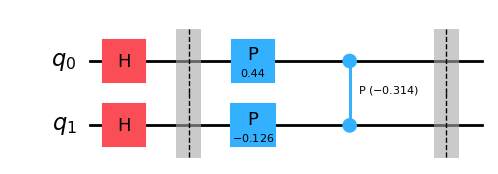

In [40]:
bose_circuit = QuantumCircuit(2)

# Initial spatial superposition
bose_circuit.h(0)
bose_circuit.h(1)
bose_circuit.barrier()

# Gravitational interaction U_grav
bose_circuit.p(dphi_RL, 0)
bose_circuit.p(dphi_LR, 1)
bose_circuit.cp(-(dphi_RL + dphi_LR), 0, 1)
bose_circuit.barrier()

bose_circuit.draw('mpl', style='iqp')

In [41]:
bose_state = Statevector(bose_circuit)
bose_state.draw('latex')

<IPython.core.display.Latex object>

In [42]:
ZX = SparsePauliOp.from_list([("ZX", 1.0)])
YY = SparsePauliOp.from_list([("YY", 1.0)])

In [43]:
def calculate_witness(state):
    # Calculate W = | <ZX> + <YY> |

    zx = state.expectation_value(ZX).real
    yy = state.expectation_value(YY).real

    W = abs(zx + yy)

    return zx, yy, W

In [44]:
zx_phys, yy_phys, W_phys = calculate_witness(bose_state)

print("Physical Bose result")
print("--------------------------------")
print(f"<ZX> = {zx_phys:+.10f}")
print(f"<YY> = {yy_phys:+.10f}")
print(f"W    = {W_phys:.10f}")

if W_phys > 1:
    print("Entanglement certified: W > 1")
else:
    print("No entanglement certified: W <= 1")

Physical Bose result
--------------------------------
<ZX> = -0.0435824866
<YY> = -0.0777276765
W    = 0.1213101631
No entanglement certified: W <= 1


In [45]:
def analytic_witness(lambda_value):
    # Analytic Bose witness for a given phase scaling lambda.

    phi_RL = lambda_value * dphi_RL
    phi_LR = lambda_value * dphi_LR

    zx = (np.cos(phi_RL) - np.cos(phi_LR)) / 2
    yy = (np.cos(phi_RL - phi_LR) - 1) / 2

    W = abs(zx + yy)

    return zx, yy, W

In [46]:
zx_an, yy_an, W_an = analytic_witness(1.0)

print("Analytical result")
print("--------------------------------")
print(f"<ZX> = {zx_an:+.10f}")
print(f"<YY> = {yy_an:+.10f}")
print(f"W    = {W_an:.10f}")

Analytical result
--------------------------------
<ZX> = -0.0435824866
<YY> = -0.0777276765
W    = 0.1213101631


In [47]:
print("Difference between analytical and Qiskit results")
print("--------------------------------")
print(f"ZX difference = {abs(zx_an - zx_phys):.3e}")
print(f"YY difference = {abs(yy_an - yy_phys):.3e}")
print(f"W difference  = {abs(W_an - W_phys):.3e}")

Difference between analytical and Qiskit results
--------------------------------
ZX difference = 0.000e+00
YY difference = 5.551e-17
W difference  = 5.551e-17


In [48]:
lambda_var = Parameter("lambda")

In [49]:
def bose_vqe_circuit(
    lambda_parameter,
    dphi_RL_phys,
    dphi_LR_phys
):
    """
    Parameterized Bose QGEM circuit.

    lambda_parameter scales both gravitational phases
    while preserving their physical ratio.
    """

    qc = QuantumCircuit(2)

    # --------------------------------------------------------
    # Initial superposition
    # --------------------------------------------------------

    qc.h(0)
    qc.h(1)
    qc.barrier(label="SG")

    # --------------------------------------------------------
    # Parameterized gravitational phases
    # --------------------------------------------------------

    phi_RL = (lambda_parameter * dphi_RL_phys)

    phi_LR = (lambda_parameter * dphi_LR_phys)

    # --------------------------------------------------------
    # U_grav
    # --------------------------------------------------------

    qc.p(phi_RL, 0)
    qc.p(phi_LR, 1)
    qc.cp(-(phi_RL + phi_LR), 0, 1)
    qc.barrier(label="U_grav")

    return qc

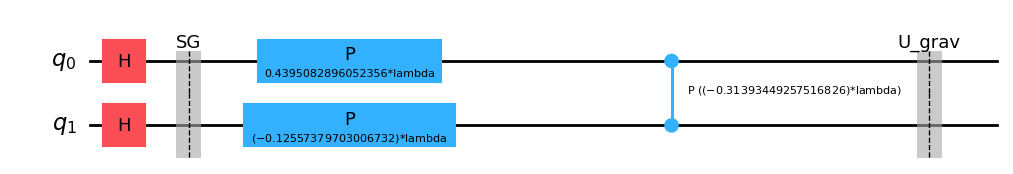

In [50]:
ansatz = bose_vqe_circuit(
    lambda_var,
    dphi_RL,
    dphi_LR
)

ansatz.draw('mpl', style='iqp')

In [51]:
H_vqe = SparsePauliOp.from_list([
    ("ZX", 1.0),
    ("YY", 1.0)
])

In [52]:
lambda_scan = np.linspace(0, 10, 1000)
witness_scan = []
energy_scan = []

for lam in lambda_scan:

    zx, yy, W = analytic_witness(lam)
    witness_scan.append(W)
    energy_scan.append(zx + yy)

witness_scan = np.array(witness_scan)
energy_scan = np.array(energy_scan)

In [53]:
scan_index = np.argmax(witness_scan)

lambda_scan_max = (lambda_scan[scan_index])

W_scan_max = (witness_scan[scan_index])

print("Parameter scan")
print("--------------------------------")
print(f"Best scanned lambda = {lambda_scan_max:.6f}")
print(f"Best scanned W      = {W_scan_max:.6f}")

Parameter scan
--------------------------------
Best scanned lambda = 5.975976
Best scanned W      = 1.787040


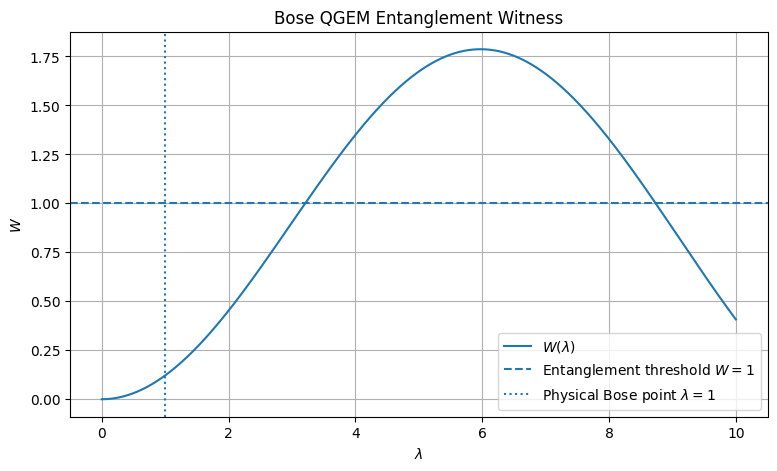

In [54]:
plt.figure(figsize=(9, 5))

plt.plot(
    lambda_scan,
    witness_scan,
    label=r"$W(\lambda)$"
)

plt.axhline(
    1.0,
    linestyle="--",
    label=r"Entanglement threshold $W=1$"
)

plt.axvline(
    1.0,
    linestyle=":",
    label=r"Physical Bose point $\lambda=1$"
)

plt.xlabel(r"$\lambda$")
plt.ylabel(r"$W$")
plt.title(
    "Bose QGEM Entanglement Witness"
)

plt.legend()
plt.grid(True)

plt.show()

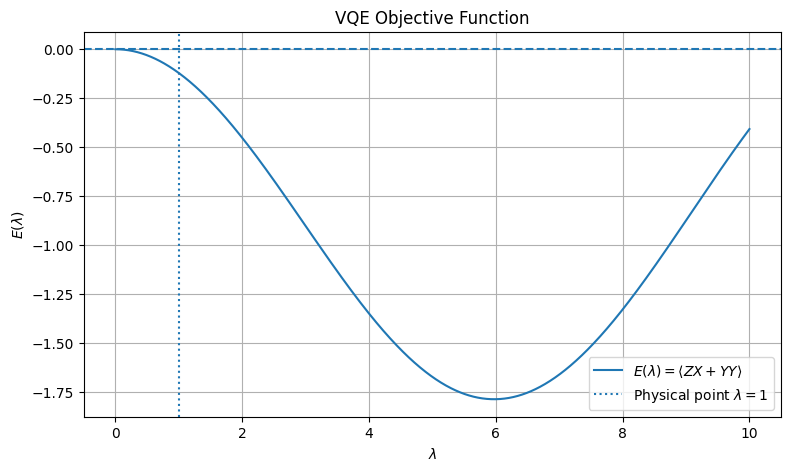

In [55]:
plt.figure(figsize=(9, 5))

plt.plot(
    lambda_scan,
    energy_scan,
    label=r"$E(\lambda)=\langle ZX+YY\rangle$"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    1.0,
    linestyle=":",
    label=r"Physical point $\lambda=1$"
)

plt.xlabel(r"$\lambda$")
plt.ylabel(r"$E(\lambda)$")
plt.title(
    "VQE Objective Function"
)

plt.legend()
plt.grid(True)

plt.show()

In [56]:
LAMBDA_MIN = 0.0
LAMBDA_MAX = 10.0

ansatz.parameter_bounds = [(LAMBDA_MIN, LAMBDA_MAX)]

optimizer = SLSQP(
    maxiter=100,
    ftol=1e-10
)

In [57]:
vqe_history = []

def store_intermediate_result(
    eval_count,
    parameters,
    mean,
    metadata
):

    vqe_history.append({
        "iteration": eval_count,
        "lambda": float(parameters[0]),
        "energy": float(np.real(mean))
    })

In [58]:
estimator = StatevectorEstimator()

In [59]:
vqe = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    initial_point=[1.0],
    callback=store_intermediate_result
)

initial_point=[1.0]

result = vqe.compute_minimum_eigenvalue(
    operator=H_vqe
)

lambda_opt = result.optimal_point[0]
energy_opt = result.eigenvalue.real

print("VQE result")
print("--------------------------------")
print(f"Optimal lambda = {lambda_opt:.10f}")
print(f"Minimum energy = {energy_opt:.10f}")

VQE result
--------------------------------
Optimal lambda = 5.9741883131
Minimum energy = -1.7870403133


In [60]:
optimized_circuit = ansatz.assign_parameters(
    {
        lambda_var: lambda_opt
    }
)

optimized_state = Statevector(optimized_circuit)

In [61]:
zx_opt, yy_opt, W_opt = calculate_witness(
    optimized_state
)

print("Optimized witness")
print("--------------------------------")
print(f"lambda = {lambda_opt:.10f}")
print(f"<ZX>   = {zx_opt:+.10f}")
print(f"<YY>   = {yy_opt:+.10f}")
print(f"W      = {W_opt:.10f}")

if W_opt > 1:
    print("ENTANGLEMENT CERTIFIED: W > 1")
else:
    print("No entanglement certified: W <= 1")

Optimized witness
--------------------------------
lambda = 5.9741883131
<ZX>   = -0.8007034087
<YY>   = -0.9863369046
W      = 1.7870403133
ENTANGLEMENT CERTIFIED: W > 1


In [62]:
zx_vqe_an, yy_vqe_an, W_vqe_an = (
    analytic_witness(lambda_opt)
)

print("VQE / analytical comparison")
print("--------------------------------")
print(f"Qiskit <ZX> = {zx_opt:+.10f}")
print(f"Analytic    = {zx_vqe_an:+.10f}")
print()

print(f"Qiskit <YY> = {yy_opt:+.10f}")
print(f"Analytic    = {yy_vqe_an:+.10f}")
print()

print(f"Qiskit W    = {W_opt:.10f}")
print(f"Analytic W  = {W_vqe_an:.10f}")

VQE / analytical comparison
--------------------------------
Qiskit <ZX> = -0.8007034087
Analytic    = -0.8007034087

Qiskit <YY> = -0.9863369046
Analytic    = -0.9863369046

Qiskit W    = 1.7870403133
Analytic W  = 1.7870403133


In [63]:
history_iterations = np.array([
    item["iteration"]
    for item in vqe_history
])

history_lambda = np.array([
    item["lambda"]
    for item in vqe_history
])

history_energy = np.array([
    item["energy"]
    for item in vqe_history
])

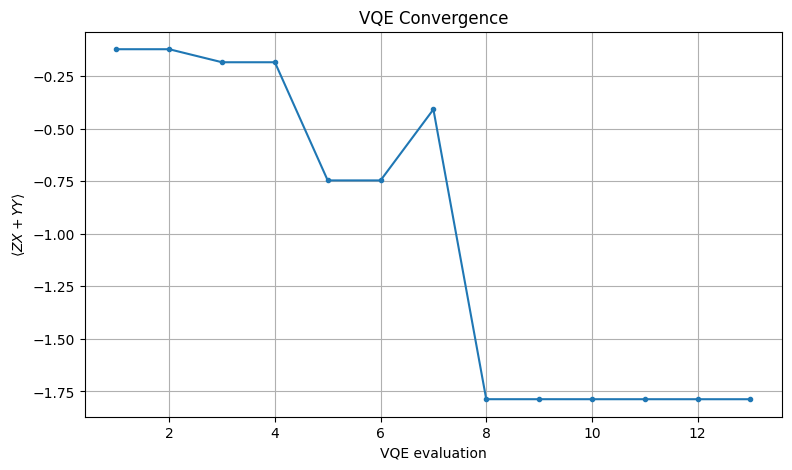

In [64]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_iterations,
    history_energy,
    marker="o",
    markersize=3
)

plt.xlabel("VQE evaluation")
plt.ylabel(r"$\langle ZX+YY\rangle$")
plt.title(
    "VQE Convergence"
)

plt.grid(True)

plt.show()

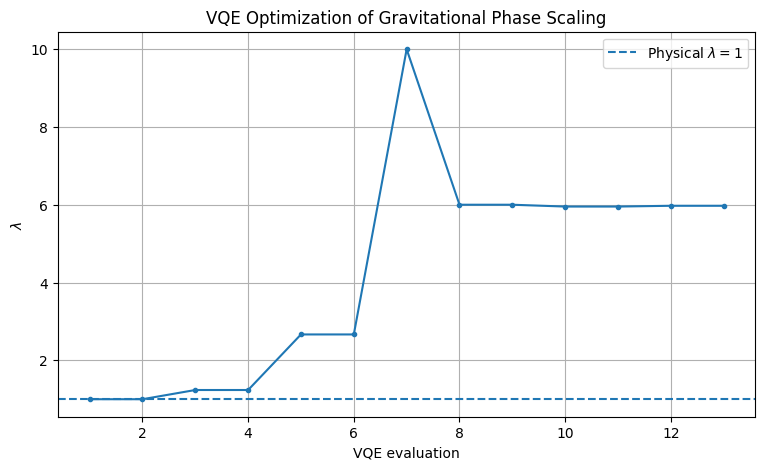

In [65]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_iterations,
    history_lambda,
    marker="o",
    markersize=3
)

plt.axhline(
    1.0,
    linestyle="--",
    label=r"Physical $\lambda=1$"
)

plt.xlabel("VQE evaluation")
plt.ylabel(r"$\lambda$")
plt.title(
    "VQE Optimization of Gravitational Phase Scaling"
)

plt.legend()
plt.grid(True)

plt.show()

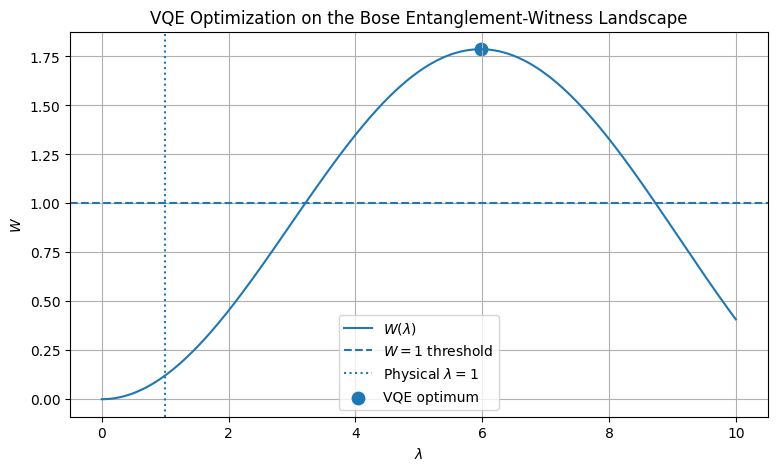

In [66]:
plt.figure(figsize=(9, 5))

plt.plot(
    lambda_scan,
    witness_scan,
    label=r"$W(\lambda)$"
)

plt.axhline(
    1.0,
    linestyle="--",
    label=r"$W=1$ threshold"
)

plt.axvline(
    1.0,
    linestyle=":",
    label=r"Physical $\lambda=1$"
)

plt.scatter(
    [lambda_opt],
    [W_opt],
    s=80,
    label=r"VQE optimum"
)

plt.xlabel(r"$\lambda$")
plt.ylabel(r"$W$")
plt.title(
    "VQE Optimization on the Bose Entanglement-Witness Landscape"
)

plt.legend()
plt.grid(True)

plt.show()

In [67]:
# ------------------------------------------------------------
# Case 1: No gravity
# ------------------------------------------------------------

lambda_zero = 0.0

zx_zero, yy_zero, W_zero = (
    analytic_witness(lambda_zero)
)


# ------------------------------------------------------------
# Case 2: Physical Bose point
# ------------------------------------------------------------

lambda_physical = 1.0

zx_physical, yy_physical, W_physical = (
    analytic_witness(lambda_physical)
)


# ------------------------------------------------------------
# Case 3: VQE optimum
# ------------------------------------------------------------

zx_vqe, yy_vqe, W_vqe = (
    analytic_witness(lambda_opt)
)

In [68]:
print("=" * 70)
print("Bose QGEM: Comparison")
print("=" * 70)

print(
    f"{'Case':<20}"
    f"{'lambda':>12}"
    f"{'<ZX>':>15}"
    f"{'<YY>':>15}"
    f"{'W':>15}"
)

print("-" * 70)

print(
    f"{'No gravity':<20}"
    f"{lambda_zero:>12.6f}"
    f"{zx_zero:>15.6f}"
    f"{yy_zero:>15.6f}"
    f"{W_zero:>15.6f}"
)

print(
    f"{'Physical Bose':<20}"
    f"{lambda_physical:>12.6f}"
    f"{zx_physical:>15.6f}"
    f"{yy_physical:>15.6f}"
    f"{W_physical:>15.6f}"
)

print(
    f"{'VQE optimum':<20}"
    f"{lambda_opt:>12.6f}"
    f"{zx_vqe:>15.6f}"
    f"{yy_vqe:>15.6f}"
    f"{W_vqe:>15.6f}"
)

print("=" * 70)

Bose QGEM: Comparison
Case                      lambda           <ZX>           <YY>              W
----------------------------------------------------------------------
No gravity              0.000000       0.000000       0.000000       0.000000
Physical Bose           1.000000      -0.043582      -0.077728       0.121310
VQE optimum             5.974188      -0.800703      -0.986337       1.787040


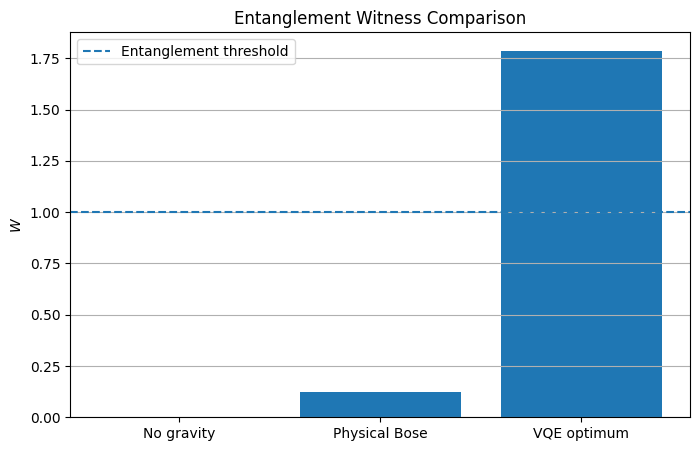

In [69]:
labels = [
    "No gravity",
    "Physical Bose",
    "VQE optimum"
]

values = [
    W_zero,
    W_physical,
    W_vqe
]

plt.figure(figsize=(8, 5))

plt.bar(
    labels,
    values
)

plt.axhline(
    1.0,
    linestyle="--",
    label="Entanglement threshold"
)

plt.ylabel(r"$W$")
plt.title(
    "Entanglement Witness Comparison"
)

plt.legend()
plt.grid(axis="y")

plt.show()

In [70]:
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel

# 1. Load local backend snapshot (No account/token required)
backend = FakeBrisbane()
print(f"Simulating target system: {backend.name}")

# 2. Extract noise model and initialize Aer Simulator
noise_model = NoiseModel.from_backend(backend)
backend_sim = AerSimulator(noise_model=noise_model)

# 3. Use the Estimator with the local Aer simulator backend
estimator = Estimator(mode=backend_sim)

Simulating target system: fake_brisbane


In [71]:
from qiskit.quantum_info import SparsePauliOp
import numpy as np

# Qubit Hamiltonian of the hydrogen atom generated by using STO-3G basis set and parity mapping
Hamiltonian = SparsePauliOp.from_list([("I", -0.2355), ("Z", 0.2355)])

# exact ground state energy of Hamiltonian

A = np.array(Hamiltonian)
eigenvalues, eigenvectors = np.linalg.eig(A)
print(
    "The exact ground state energy of the Hamiltonian is ",
    min(eigenvalues).real,
    "hartree",
)
h = min(eigenvalues.real)

The exact ground state energy of the Hamiltonian is  -0.471 hartree


In [72]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector, DensityMatrix, Pauli

theta = Parameter("θ")
phi = Parameter("φ")
lam = Parameter("λ")

ansatz1 = QuantumCircuit(1)
ansatz1.rx(theta, 0)

ansatz2 = QuantumCircuit(1)
ansatz2.rx(theta, 0)
ansatz2.rz(phi, 0)

ansatz3 = QuantumCircuit(1)
ansatz3.rx(theta, 0)
ansatz3.rz(phi, 0)
ansatz3.rx(lam, 0)

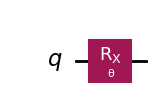

In [73]:
ansatz1.draw('mpl')

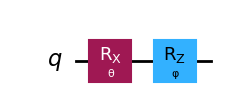

In [74]:
ansatz2.draw('mpl')

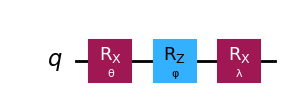

In [75]:
ansatz3.draw('mpl')

In [76]:
import matplotlib.pyplot as plt


def plot_bloch(bloch_vectors):
    # Extract X, Y, Z coordinates for 3D projection
    X_coords = bloch_vectors[:, 0]
    Z_coords = bloch_vectors[:, 2]

    # Compute Y coordinates from X and Z to approximate the full Bloch sphere projection
    Y_coords = bloch_vectors[:, 1]

    # Determine dominant axis direction for each point: 0->X, 1->Y, 2->Z
    dominant_axes = np.argmax(np.abs(bloch_vectors), axis=1)

    # Map dominant axis to target colors: X -> blue, Y -> red, Z -> green
    color_map = np.array(["blue", "red", "green"])
    point_colors = color_map[dominant_axes]

    # Create 3D plot
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection="3d")

    # Scatter plot with custom per-point colors
    ax.scatter(X_coords, Y_coords, Z_coords, c=point_colors, alpha=0.6, s=10)

    # Labels and title
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_title("Parameterized 1-Qubit Circuit on 3D Bloch Sphere")

    # Set axis limits and make them equal
    ax.set_xlim([-1, 1])
    ax.set_ylim([-1, 1])
    ax.set_zlim([-1, 1])

    # Ensure equal aspect ratio for all axes
    ax.set_box_aspect([1, 1, 1])  # Equal scaling for x, y, z axes

    # Show grid
    ax.grid(True)

    plt.show()


num_samples = 5000  # Number of random states
theta_vals = np.random.uniform(0, 2 * np.pi, num_samples)
phi_vals = np.random.uniform(0, 2 * np.pi, num_samples)
lam_vals = np.random.uniform(0, 2 * np.pi, num_samples)

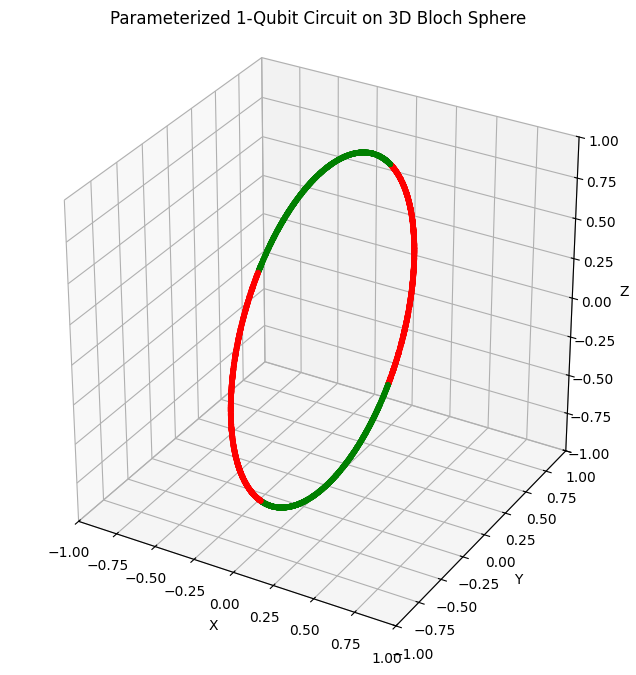

In [77]:
# List to store Bloch Sphere XZ coordinates
bloch_vectors = []

# Generate quantum states and extract Bloch vectors
for i in range(num_samples):
    # Create a circuit and bind parameters
    qc = ansatz1
    bound_qc = qc.assign_parameters({theta: theta_vals[i]})  # , lam: lam_vals[i]})
    state = Statevector.from_instruction(bound_qc)
    rho = DensityMatrix(state)

    X = rho.expectation_value(Pauli("X")).real
    Y = rho.expectation_value(Pauli("Y")).real
    Z = rho.expectation_value(Pauli("Z")).real
    bloch_vectors.append([X, Y, Z])  # Store X, Z components

# Convert to a numpy array for plotting
bloch_vectors = np.array(bloch_vectors)

plot_bloch(bloch_vectors)

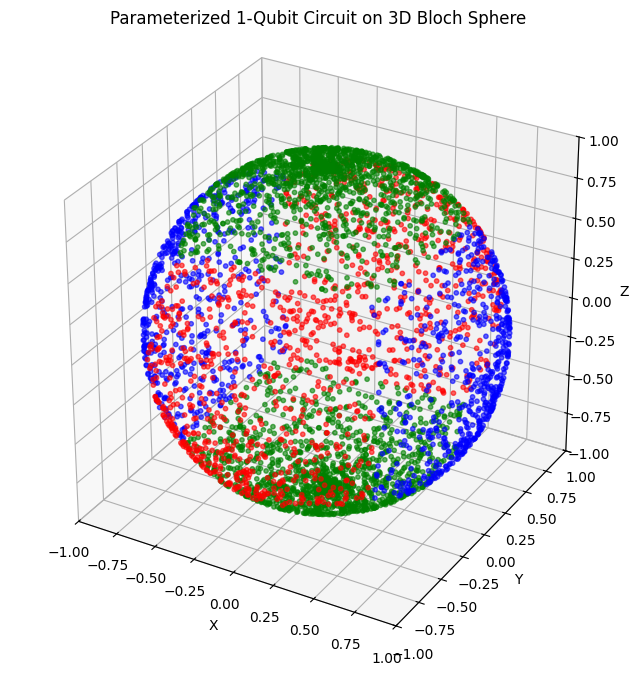

In [78]:
bloch_vectors = []

# Generate quantum states and extract Bloch vectors
for i in range(num_samples):
    # Create circuit and bind parameters
    qc = ansatz2
    bound_qc = qc.assign_parameters(
        {theta: theta_vals[i], phi: phi_vals[i]}
    )  # , lam: lam_vals[i]})
    state = Statevector.from_instruction(bound_qc)
    rho = DensityMatrix(state)

    X = rho.expectation_value(Pauli("X")).real
    Y = rho.expectation_value(Pauli("Y")).real
    Z = rho.expectation_value(Pauli("Z")).real
    bloch_vectors.append([X, Y, Z])  # Store X, Z components

# Convert to numpy array for plotting
bloch_vectors = np.array(bloch_vectors)

plot_bloch(bloch_vectors)

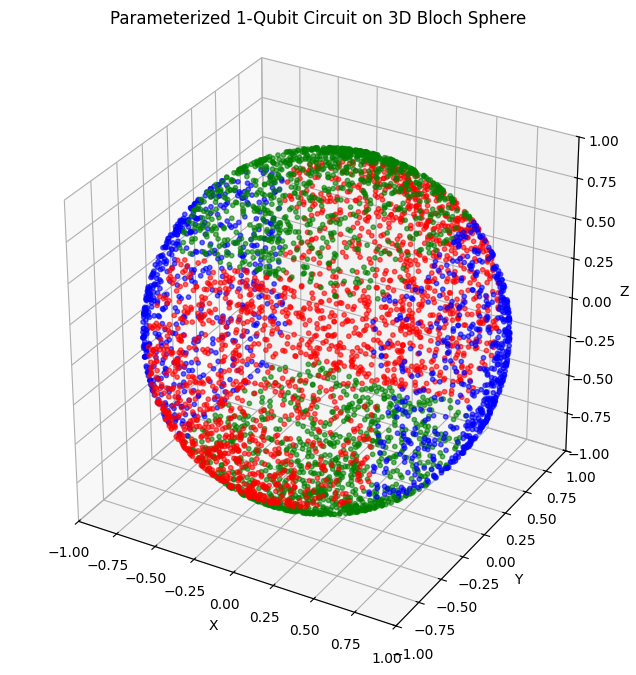

In [79]:
bloch_vectors = []

# Generate quantum states and extract Bloch vectors
for i in range(num_samples):
    # Create circuit and bind parameters
    qc = ansatz3
    bound_qc = qc.assign_parameters(
        {theta: theta_vals[i], phi: phi_vals[i], lam: lam_vals[i]}
    )
    state = Statevector.from_instruction(bound_qc)
    rho = DensityMatrix(state)

    X = rho.expectation_value(Pauli("X")).real
    Y = rho.expectation_value(Pauli("Y")).real
    Z = rho.expectation_value(Pauli("Z")).real
    bloch_vectors.append([X, Y, Z])  # Store X, Z components

# Convert to numpy array for plotting
bloch_vectors = np.array(bloch_vectors)

plot_bloch(bloch_vectors)

This circuit has  3 parameters


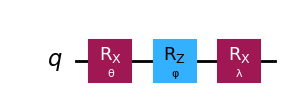

In [80]:
# Pre-defined ansatz circuit and operator class for Hamiltonian
ansatz = ansatz3

num_params = ansatz.num_parameters
print("This circuit has ", num_params, "parameters")

ansatz.draw("mpl", style="iqp")

Backend: {config.backend_name}
Native gates:  ['ecr', 'id', 'delay', 'measure', 'reset', 'rz', 'sx', 'x', 'if_else', 'for_loop', 'switch_case'] ,


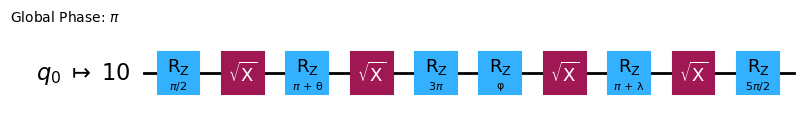

In [81]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

config = backend.configuration()

print("Backend: {config.backend_name}")
print("Native gates: ", config.supported_instructions, ",")


target = backend.target

pm = generate_preset_pass_manager(target=target, optimization_level=3)

ansatz_isa = pm.run(ansatz)

ansatz_isa.draw(output="mpl", idle_wires=False, style="iqp")

In [82]:
Hamiltonian_isa = Hamiltonian.apply_layout(layout=ansatz_isa.layout)

In [83]:
def cost_func(params, ansatz, hamiltonian, estimator):
    """Return estimate of energy from estimator

    Parameters:
        params (ndarray): Array of ansatz parameters
        ansatz (QuantumCircuit): Parameterized ansatz circuit
        hamiltonian (SparsePauliOp): Operator representation of Hamiltonian
        estimator (EstimatorV2): Estimator primitive instance
        cost_history_dict: Dictionary for storing intermediate results

    Returns:
        float: Energy estimate
    """
    pub = (ansatz, [hamiltonian], [params])
    result = estimator.run(pubs=[pub]).result()
    energy = result[0].data.evs[0]

    cost_history_dict["iters"] += 1
    cost_history_dict["prev_vector"] = params
    cost_history_dict["cost_history"].append(energy)
    print(f"Iters. done: {cost_history_dict['iters']} [Current cost: {energy}]")

    return energy

In [84]:
# x0 = np.random.uniform(0, 2*pi, 3)
x0 = [1, 1, 0]

In [85]:
# QPU Est. 2min for ibm_brisbane

from scipy.optimize import minimize
from qiskit_ibm_runtime import Batch

batch = Batch(backend=backend)

cost_history_dict = {
    "prev_vector": None,
    "iters": 0,
    "cost_history": [],
}
estimator = Estimator(mode=batch)
estimator.options.default_shots = 10000

res = minimize(
    cost_func,
    x0,
    args=(ansatz_isa, Hamiltonian_isa, estimator),
    method="cobyla",
    options={"maxiter": 10, "tol": 0.01},
)

batch.close()

Iters. done: 1 [Current cost: -0.32725079999999995]
Iters. done: 2 [Current cost: -0.45710549999999994]
Iters. done: 3 [Current cost: -0.3778833]
Iters. done: 4 [Current cost: -0.3768471]
Iters. done: 5 [Current cost: -0.4514064]
Iters. done: 6 [Current cost: -0.39615809999999996]
Iters. done: 7 [Current cost: -0.45159479999999996]
Iters. done: 8 [Current cost: -0.45785909999999996]
Iters. done: 9 [Current cost: -0.4576236]
Iters. done: 10 [Current cost: -0.45851849999999994]


In [86]:
h_vqe = res.fun
print("The reference ground state energy is ", min(eigenvalues))
print("The computed ground state energy is ", h_vqe)

The reference ground state energy is  (-0.471+0j)
The computed ground state energy is  -0.45851849999999994


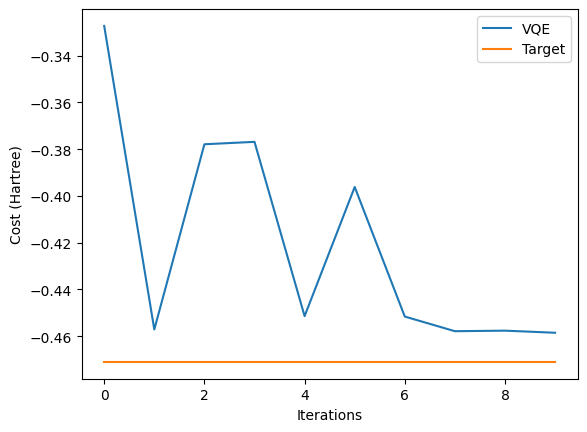

In [87]:
fig, ax = plt.subplots()
x = np.linspace(0, 10, 10)

# Define the constant function
y_constant = np.full_like(x, h)
ax.plot(
    range(cost_history_dict["iters"]), cost_history_dict["cost_history"], label="VQE"
)
ax.set_xlabel("Iterations")
ax.set_ylabel("Cost (Hartree)")
ax.plot(y_constant, label="Target")
plt.legend()
plt.draw()

In [89]:
h2_hamiltonian = SparsePauliOp.from_list(
    [("I", -1.04886087), ("Z", -0.7967368), ("X", 0.18121804)]
)

# exact ground state energy of hamiltonian
nuclear_repulsion = 0.71997
A = np.array(h2_hamiltonian)
eigenvalues, eigenvectors = np.linalg.eig(A)
print("Electronic ground state energy (Hartree): ", min(eigenvalues).real)
print("Nuclear repulsion energy (Hartree): ", nuclear_repulsion)
print("Total ground state energy (Hartree): ", min(eigenvalues).real + nuclear_repulsion)
h2 = min(eigenvalues).real + nuclear_repulsion

Electronic ground state energy (Hartree):  -1.8659468547627318
Nuclear repulsion energy (Hartree):  0.71997
Total ground state energy (Hartree):  -1.1459768547627318


In [90]:
h2_hamiltonian_isa = h2_hamiltonian.apply_layout(layout=ansatz_isa.layout)

In [91]:
x0 = [2, 0, 0]

In [92]:
# QPU time 4min for ibm_brisbane
batch = Batch(backend=backend)

cost_history_dict = {
    "prev_vector": None,
    "iters": 0,
    "cost_history": [],
}
estimator = Estimator(mode=batch)
estimator.options.default_shots = 10000

res = minimize(
    cost_func,
    x0,
    args=(ansatz_isa, h2_hamiltonian_isa, estimator),
    method="cobyla",
    options={"maxiter": 15},
)

batch.close()

Iters. done: 1 [Current cost: -0.7206378165519999]
Iters. done: 2 [Current cost: -0.3035351529919999]
Iters. done: 3 [Current cost: -0.29722500290399995]
Iters. done: 4 [Current cost: -0.5976926498799999]
Iters. done: 5 [Current cost: -1.702479272376]
Iters. done: 6 [Current cost: -0.687071147576]
Iters. done: 7 [Current cost: -1.592655080672]
Iters. done: 8 [Current cost: -1.835458041624]
Iters. done: 9 [Current cost: -1.7356832905519999]
Iters. done: 10 [Current cost: -1.841523878776]
Iters. done: 11 [Current cost: -1.7815074694479998]
Iters. done: 12 [Current cost: -1.8390993193360001]
Iters. done: 13 [Current cost: -1.8320255094959998]
Iters. done: 14 [Current cost: -1.812843248544]
Iters. done: 15 [Current cost: -1.84102648316]


In [93]:
h2_vqe = res.fun + nuclear_repulsion
print("The reference ground state energy is ", min(eigenvalues).real + nuclear_repulsion)
print("The computed ground state energy is ", h2_vqe)

The reference ground state energy is  -1.1459768547627318
The computed ground state energy is  -1.121553878776


c:\projects\qiskit_projects\.venv\Lib\site-packages\numpy\_core\numeric.py:475: ComplexWarning: Casting complex values to real discards the imaginary part
  multiarray.copyto(res, fill_value, casting='unsafe')


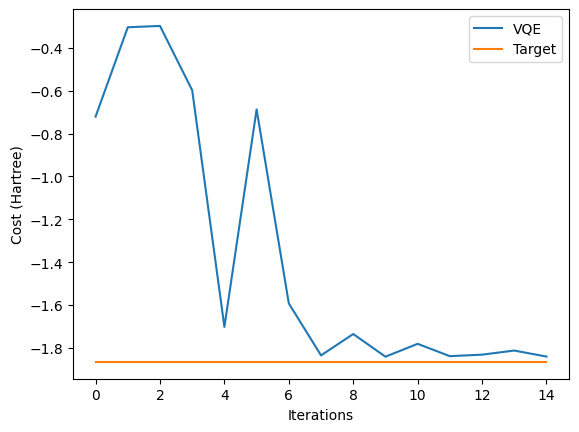

In [94]:
fig, ax = plt.subplots()
x = np.linspace(0, 5, 15)

# Define the constant function
y_constant = np.full_like(x, min(eigenvalues))
ax.plot(
    range(cost_history_dict["iters"]), cost_history_dict["cost_history"], label="VQE"
)
ax.set_xlabel("Iterations")
ax.set_ylabel("Cost (Hartree)")
ax.plot(y_constant, label="Target")
plt.legend()
plt.draw()

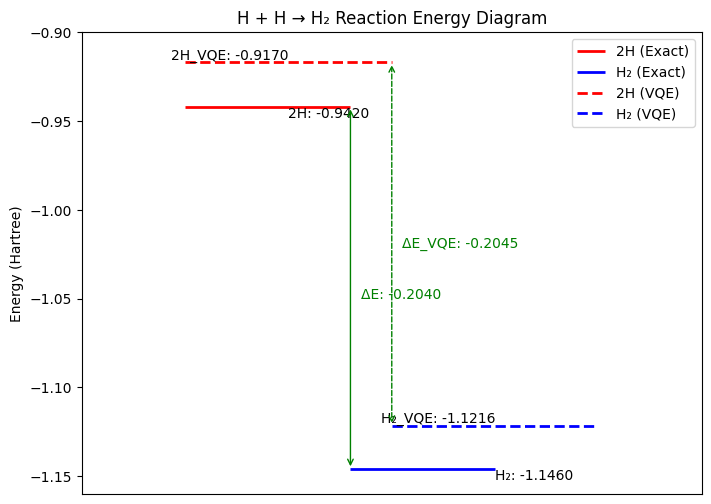

In [97]:
# Theoretical values
E_H_theo = h.real
E_H2_theo = h2

# Experimental values
E_H_exp = h_vqe
E_H2_exp = h2_vqe

# Calculate reaction energies
E_reaction_theo = E_H2_theo - (2 * E_H_theo)
E_reaction_exp = E_H2_exp - (2 * E_H_exp)

# Set up the plot
fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(0, 3)
ax.set_ylim(-1.16, -0.9)  # Adjust y-axis range to highlight differences
ax.set_xticks([])
ax.set_ylabel("Energy (Hartree)")
ax.set_title("H + H → H₂ Reaction Energy Diagram")

# Plot theoretical energy levels
ax.hlines(
    y=2 * E_H_theo, xmin=0.5, xmax=1.3, linewidth=2, color="r", label="2H (Exact)"
)
ax.hlines(y=E_H2_theo, xmin=1.3, xmax=2, linewidth=2, color="b", label="H₂ (Exact)")

# Plot experimental energy levels
ax.hlines(
    y=2 * E_H_exp,
    xmin=0.5,
    xmax=1.5,
    linewidth=2,
    color="r",
    linestyle="dashed",
    label="2H (VQE)",
)
ax.hlines(
    y=E_H2_exp,
    xmin=1.5,
    xmax=2.5,
    linewidth=2,
    color="b",
    linestyle="dashed",
    label="H₂ (VQE)",
)

# Add labels
ax.text(
    1,
    2 * E_H_theo,
    f"2H: {2*E_H_theo:.4f}",
    verticalalignment="top",
    horizontalalignment="left",
)
ax.text(
    2,
    E_H2_theo,
    f"H₂: {E_H2_theo:.4f}",
    verticalalignment="top",
    horizontalalignment="left",
)
ax.text(
    1,
    2 * E_H_exp,
    f"2H_VQE: {2*E_H_exp:.4f}",
    verticalalignment="bottom",
    horizontalalignment="right",
)
ax.text(
    2,
    E_H2_exp,
    f"H₂_VQE: {E_H2_exp:.4f}",
    verticalalignment="bottom",
    horizontalalignment="right",
)

# Add arrows for reaction energy with ΔE label in the middle
mid_y_theo = (2 * E_H_theo + E_H2_theo) / 2
mid_y_exp = (2 * E_H_exp + E_H2_exp) / 2
ax.annotate(
    "",
    xy=(1.3, E_H2_theo),
    xytext=(1.3, 2 * E_H_theo),
    arrowprops=dict(arrowstyle="<->", color="g"),
)
ax.text(
    1.35, mid_y_theo, f"ΔE: {E_reaction_theo:.4f}", color="g", verticalalignment="top"
)

ax.annotate(
    "",
    xy=(1.5, E_H2_exp),
    xytext=(1.5, 2 * E_H_exp),
    arrowprops=dict(arrowstyle="<->", color="g", linestyle="dashed"),
)
ax.text(
    1.55,
    mid_y_exp,
    f"ΔE_VQE: {E_reaction_exp:.4f}",
    color="g",
    verticalalignment="center",
)

# Add legend
ax.legend()

plt.show()

In [98]:
from qiskit.circuit import ParameterVector

num_iter = 4
alpha = ParameterVector("alpha", 3)
beta = ParameterVector("beta", 3 * num_iter)

# step1: Map problem to quantum circuits and operators
hamiltonian = SparsePauliOp.from_list(
    [("I", -1.04886087), ("Z", -0.7967368), ("X", 0.18121804)]
)

ansatz_1 = ansatz3
ansatz_2 = QuantumCircuit(1)
for i in range(num_iter):
    ansatz_2.rx(beta[i * 3 + 0], 0)
    ansatz_2.rz(beta[i * 3 + 1], 0)
    ansatz_2.rx(beta[i * 3 + 2], 0)

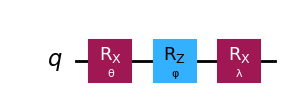

In [99]:
ansatz_1.draw('mpl')

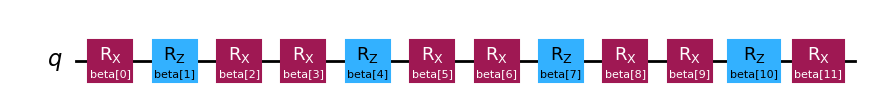

In [100]:
ansatz_2.draw('mpl')

In [101]:
# Step 2: Optimize for target hardware

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

ansatz_isa_1 = pm.run(ansatz_1)
ansatz_isa_2 = pm.run(ansatz_2)
hamiltonian_isa_1 = hamiltonian.apply_layout(layout=ansatz_isa_1.layout)
hamiltonian_isa_2 = hamiltonian.apply_layout(layout=ansatz_isa_2.layout)

In [102]:
# QPU time 3m 40s for ibm_brisbane
# Step 3: Execute on target hardware

from scipy.optimize import minimize

x0 = np.ones(ansatz_1.num_parameters)

batch = Batch(backend=backend)


cost_history_dict = {
    "prev_vector": None,
    "iters": 0,
    "cost_history": [],
}
estimator = Estimator(mode=batch)
estimator.options.default_shots = 2048

res = minimize(
    cost_func,
    x0,
    args=(ansatz_isa_1, hamiltonian_isa_1, estimator),
    method="cobyla",
    options={"maxiter": 20},
)

batch.close()

Iters. done: 1 [Current cost: -0.8217273347925816]
Iters. done: 2 [Current cost: -0.42976874722791597]
Iters. done: 3 [Current cost: -0.43670686845778417]
Iters. done: 4 [Current cost: -1.390177419751098]
Iters. done: 5 [Current cost: -1.758942492430454]
Iters. done: 6 [Current cost: -1.5098273477550024]
Iters. done: 7 [Current cost: -1.3179561562274278]
Iters. done: 8 [Current cost: -1.7875886455197658]
Iters. done: 9 [Current cost: -1.752577693445583]
Iters. done: 10 [Current cost: -1.78292254420205]
Iters. done: 11 [Current cost: -1.797064178716447]
Iters. done: 12 [Current cost: -1.7694975624938993]
Iters. done: 13 [Current cost: -1.7876221993313812]
Iters. done: 14 [Current cost: -1.7975612780234258]
Iters. done: 15 [Current cost: -1.8097602228745728]
Iters. done: 16 [Current cost: -1.8039260770082968]
Iters. done: 17 [Current cost: -1.7962224259785262]
Iters. done: 18 [Current cost: -1.809766299751098]
Iters. done: 19 [Current cost: -1.8106842754270376]
Iters. done: 20 [Current c

In [103]:
# Save Cost_history as a new list
ansatz_1_history = cost_history_dict["cost_history"]

In [104]:
# QPU time 3m 40s for ibm_brisbane

x0 = np.ones(ansatz_2.num_parameters)

batch = Batch(backend=backend)


cost_history_dict = {
    "prev_vector": None,
    "iters": 0,
    "cost_history": [],
}
estimator = Estimator(mode=batch)
estimator.options.default_shots = 2048

res = minimize(
    cost_func,
    x0,
    args=(ansatz_isa_2, hamiltonian_isa_2, estimator),
    method="cobyla",
    options={"maxiter": 20},
)

batch.close()

Iters. done: 1 [Current cost: -0.7755207517959979]
Iters. done: 2 [Current cost: -0.4476615458223522]
Iters. done: 3 [Current cost: -1.3484966459492436]
Iters. done: 4 [Current cost: -0.8706390988140557]
Iters. done: 5 [Current cost: -0.9476999166178623]
Iters. done: 6 [Current cost: -0.776881003899463]
Iters. done: 7 [Current cost: -1.5334022393118594]
Iters. done: 8 [Current cost: -1.641457453055149]
Iters. done: 9 [Current cost: -1.2367629286627624]
Iters. done: 10 [Current cost: -1.1353229757491459]
Iters. done: 11 [Current cost: -1.1674550318545631]
Iters. done: 12 [Current cost: -1.7871066074133724]
Iters. done: 13 [Current cost: -1.2279125021522692]
Iters. done: 14 [Current cost: -1.661768378579795]
Iters. done: 15 [Current cost: -1.8099005149975598]
Iters. done: 16 [Current cost: -1.328013734011713]
Iters. done: 17 [Current cost: -1.794621351307955]
Iters. done: 18 [Current cost: -1.5848909149975596]
Iters. done: 19 [Current cost: -1.789116535690581]
Iters. done: 20 [Current co

In [ ]:
ansatz_2_history = cost_history_dict["cost_history"]

In [ ]:
fig, ax = plt.subplots()

# Define the constant function)
ax.plot(
    range(cost_history_dict["iters"]),
    ansatz_1_history,
    label="Ansatz with 3 parameters",
)
ax.plot(
    range(cost_history_dict["iters"]),
    ansatz_2_history,
    label="Ansatz with 12 parameters",
)
ax.set_xlabel("Iterations")
ax.set_ylabel("Cost (Hartree)")
plt.legend()
plt.draw()